# Predicting customer churn for a telecom operator

**Sample project built with public data.** Data: *Iranian Churn Dataset*, UCI Machine Learning Repository
(CC BY 4.0). Analysis by Marlon Jiménez Valencia.

**Business question.** Which customers are likely to leave in the next quarter, and what can the company act on?
Each row is a customer. All features are totals for the **first 9 months**; the target (`Churn`) is the customer's
state at the **end of month 12**. The 3-month gap is built into the data, so the model predicts the future, not
the present.

**Plan.** Explore → prepare (remove duplicates, split before any fitting) → compare logistic regression, random
forest and gradient boosting with 5-fold cross-validation → pick a threshold on training data only → evaluate once
on the untouched test set → explain the drivers.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT.parent / "common"))
import brand  # noqa: E402

warnings.filterwarnings("ignore")
brand.apply_mpl_style()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160})
FIG = ROOT / "output" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42


def md(text: str) -> None:
    display(Markdown(text))

## 1. Data

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "Customer Churn.csv")
raw.columns = [" ".join(c.split()) for c in raw.columns]  # the file has double spaces in some names
NAMES = {"Call Failure": "call_failures", "Complains": "complained", "Subscription Length": "months_subscribed",
         "Charge Amount": "charge_level", "Seconds of Use": "seconds_of_use", "Frequency of use": "calls",
         "Frequency of SMS": "sms", "Distinct Called Numbers": "distinct_numbers_called", "Age Group": "age_group",
         "Tariff Plan": "contract_plan", "Status": "inactive", "Age": "age", "Customer Value": "customer_value",
         "Churn": "churn"}
df = raw.rename(columns=NAMES)
df["contract_plan"] = (df["contract_plan"] == 2).astype(int)   # 1 = pay as you go, 2 = contractual
df["inactive"] = (df["inactive"] == 2).astype(int)              # 1 = active, 2 = non-active
md(f"**{len(df):,} customers**, {df.shape[1] - 1} features, churn rate **{df['churn'].mean():.1%}**. "
   f"No missing values. Feature definitions are in the dataset documentation (UCI).")
display(df.describe().T[["mean", "std", "min", "50%", "max"]].round(1))

**3,150 customers**, 13 features, churn rate **15.7%**. No missing values. Feature definitions are in the dataset documentation (UCI).

,mean,std,min,50%,max
call_failures,7.6,7.3,0.0,6.0,36.0
complained,0.1,0.3,0.0,0.0,1.0
months_subscribed,32.5,8.6,3.0,35.0,47.0
charge_level,0.9,1.5,0.0,0.0,10.0
seconds_of_use,4472.5,4197.9,0.0,2990.0,17090.0
calls,69.5,57.4,0.0,54.0,255.0
sms,73.2,112.2,0.0,21.0,522.0
distinct_numbers_called,23.5,17.2,0.0,21.0,97.0
age_group,2.8,0.9,1.0,3.0,5.0
contract_plan,0.1,0.3,0.0,0.0,1.0


## 2. Exploration: how do churners differ?

churn,Stayed,Churned,Churned / stayed
call_failures,7.66,7.48,0.98
complained,0.02,0.40,26.16
months_subscribed,32.66,31.89,0.98
charge_level,1.08,0.23,0.21
seconds_of_use,5014.22,1566.63,0.31
calls,76.98,29.13,0.38
sms,83.87,15.80,0.19
distinct_numbers_called,25.58,12.39,0.48
age_group,2.83,2.80,0.99
contract_plan,0.09,0.01,0.13


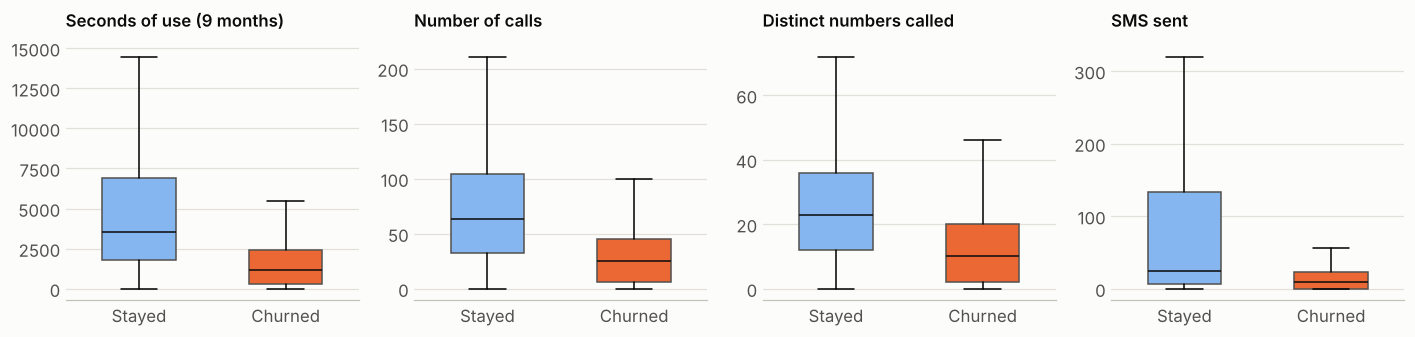

* Churners used the service far less: median seconds of use 1,182 vs 3,530.
* **Complaints:** 83% of customers who complained churned, vs 10% of those who did not.
* **Inactive status:** 47% of non-active customers churned, vs 5% of active ones.

In [3]:
comp = df.groupby("churn").mean().T.rename(columns={0: "Stayed", 1: "Churned"})
comp["Churned / stayed"] = comp["Churned"] / comp["Stayed"]
display(comp.drop(index=["age"]).round(2))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, col, title in zip(axes, ["seconds_of_use", "calls", "distinct_numbers_called", "sms"],
                          ["Seconds of use (9 months)", "Number of calls", "Distinct numbers called", "SMS sent"]):
    data = [df.loc[df["churn"] == k, col] for k in (0, 1)]
    bp = ax.boxplot(data, tick_labels=["Stayed", "Churned"], widths=0.5, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], [brand.BLUE_RAMP[3], brand.ORANGE]):
        patch.set_facecolor(c); patch.set_edgecolor(brand.INK_2)
    for med in bp["medians"]:
        med.set_color(brand.INK)
    ax.set_title(title, fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "usage_by_churn.png"); plt.show()
rate_c = df.groupby("complained")["churn"].mean()
rate_i = df.groupby("inactive")["churn"].mean()
md(f"* Churners used the service far less: median seconds of use "
   f"{df.loc[df.churn == 1, 'seconds_of_use'].median():,.0f} vs {df.loc[df.churn == 0, 'seconds_of_use'].median():,.0f}.\n"
   f"* **Complaints:** {rate_c[1]:.0%} of customers who complained churned, vs {rate_c[0]:.0%} of those who did not.\n"
   f"* **Inactive status:** {rate_i[1]:.0%} of non-active customers churned, vs {rate_i[0]:.0%} of active ones.")

## 3. Preparation (and how leakage is avoided)

* **Duplicates.** The file contains exact duplicate rows. If the same customer row sits in both the training and the
  test set, the test score is inflated, so duplicates are removed **before** splitting.
* **Redundant column.** `age` only takes 5 values and is a relabelling of `age_group`; we keep `age_group`.
* **Split first.** 25% of customers are set aside as a test set (stratified by churn) and not used until the end.
* **Scaling inside the pipeline.** For logistic regression, the scaler is part of the model pipeline, so in
  cross-validation it is fitted on each training fold only.
* **Timing.** All features describe months 1-9 and the label is month 12, so no feature contains the outcome.

In [4]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
FEATURES = ["call_failures", "complained", "months_subscribed", "charge_level", "seconds_of_use", "calls", "sms",
            "distinct_numbers_called", "age_group", "contract_plan", "inactive", "customer_value"]
X, y = df[FEATURES], df["churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
md(f"Removed **{n_before - len(df)} duplicate rows** → {len(df):,} unique customers. Training set: {len(X_tr):,} "
   f"({y_tr.mean():.1%} churn); test set: {len(X_te):,} ({y_te.mean():.1%} churn).")

Removed **300 duplicate rows** → 2,850 unique customers. Training set: 2,137 (15.6% churn); test set: 713 (15.7% churn).

## 4. Model comparison with 5-fold cross-validation (training set only)

Metrics: **ROC-AUC** (how well the model ranks churners above non-churners; 0.5 = random, 1 = perfect) and
**PR-AUC** (average precision; more informative when churners are a minority).

In [5]:
models = {
    "Logistic regression": Pipeline([("scale", ColumnTransformer([("num", StandardScaler(), FEATURES)])),
                                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample",
                                            random_state=SEED, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                        class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in models.items():
    s = cross_validate(model, X_tr, y_tr, cv=cv, scoring=["roc_auc", "average_precision"])
    rows.append({"Model": name, "ROC-AUC (mean)": s["test_roc_auc"].mean(), "ROC-AUC (sd)": s["test_roc_auc"].std(),
                 "PR-AUC (mean)": s["test_average_precision"].mean(), "PR-AUC (sd)": s["test_average_precision"].std()})
cvres = pd.DataFrame(rows).set_index("Model")
display(cvres.round(3))
best_name = cvres["PR-AUC (mean)"].idxmax()
md(f"**{best_name}** has the best cross-validated PR-AUC ({cvres.loc[best_name, 'PR-AUC (mean)']:.3f}) and ROC-AUC "
   f"({cvres.loc[best_name, 'ROC-AUC (mean)']:.3f}). Logistic regression is kept as the interpretable baseline.")

,ROC-AUC (mean),ROC-AUC (sd),PR-AUC (mean),PR-AUC (sd)
Model,,,,
Logistic regression,0.934,0.013,0.749,0.046
Random forest,0.983,0.004,0.916,0.021
Gradient boosting,0.986,0.003,0.947,0.007


**Gradient boosting** has the best cross-validated PR-AUC (0.947) and ROC-AUC (0.986). Logistic regression is kept as the interpretable baseline.

## 5. Choosing the decision threshold

A model gives a probability; the business needs a yes/no list for the retention team. The threshold is chosen on
**out-of-fold predictions from the training set** (never on the test set): we want to find **at least 80% of the
churners** (recall ≥ 0.80) and, among the thresholds that do, take the one with the **highest precision**, so the
retention team wastes as few calls as possible on customers who would have stayed.

In [6]:
best = models[best_name]
oof = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
ok = rec[:-1] >= 0.80
threshold = float(thr[ok][np.argmax(prec[:-1][ok])])
md(f"Chosen threshold: **{threshold:.2f}** (training out-of-fold: recall {recall_score(y_tr, oof >= threshold):.2f}, "
   f"precision {precision_score(y_tr, oof >= threshold):.2f}). The default 0.50 would give recall "
   f"{recall_score(y_tr, oof >= 0.5):.2f} and precision {precision_score(y_tr, oof >= 0.5):.2f}.")

Chosen threshold: **0.85** (training out-of-fold: recall 0.81, precision 0.91). The default 0.50 would give recall 0.88 and precision 0.86.

## 6. Final evaluation on the test set (used once)

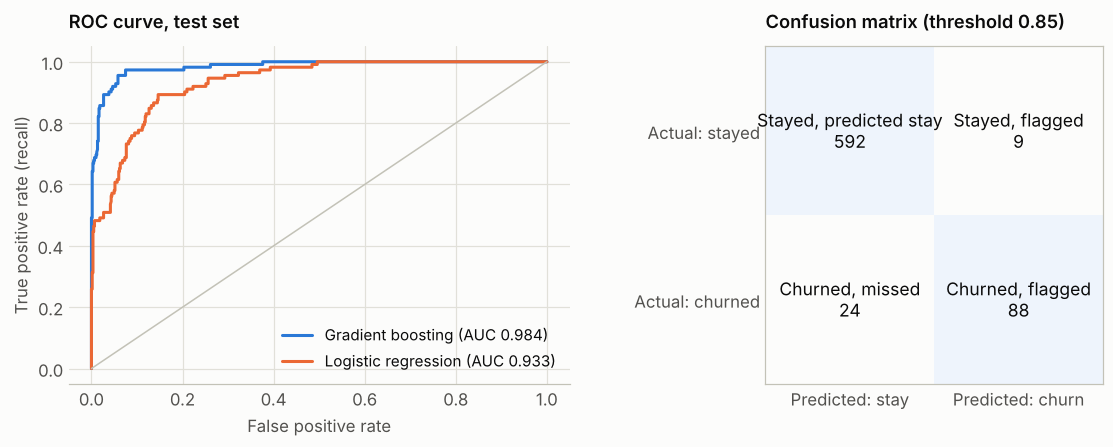

* **ROC-AUC 0.984**, PR-AUC 0.940 on 713 unseen customers (112 churners). The logistic regression baseline reaches ROC-AUC 0.933.
* At the chosen threshold the model flags **97** customers: **88 of the 112 churners are caught (recall 79%)** and 91% of the flagged customers really churn (precision). 24 churners are missed and 9 loyal customers would receive an offer they did not need.
* Test scores are close to the cross-validation scores, so there is no sign of overfitting.

In [7]:
best.fit(X_tr, y_tr)
p_te = best.predict_proba(X_te)[:, 1]
pred = (p_te >= threshold).astype(int)
cm = confusion_matrix(y_te, pred)
tn, fp, fn, tp = cm.ravel()
auc_te, ap_te = roc_auc_score(y_te, p_te), average_precision_score(y_te, p_te)
lr = models["Logistic regression"].fit(X_tr, y_tr)
p_lr = lr.predict_proba(X_te)[:, 1]
auc_lr = roc_auc_score(y_te, p_lr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for p, name, color in ((p_te, best_name, brand.BLUE), (p_lr, "Logistic regression", brand.ORANGE)):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], color=brand.AXIS, lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve, test set", fontsize=12); ax.legend(loc="lower right"); ax.grid(True)
ax = axes[1]
ax.imshow([[1, 0], [0, 1]], cmap=plt.matplotlib.colors.ListedColormap([brand.SURFACE, brand.WASH]))
labels = [[f"Stayed, predicted stay\n{tn}", f"Stayed, flagged\n{fp}"],
          [f"Churned, missed\n{fn}", f"Churned, flagged\n{tp}"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, labels[i][j], ha="center", va="center", fontsize=11.5, color=brand.INK)
ax.set_xticks([0, 1], ["Predicted: stay", "Predicted: churn"]); ax.set_yticks([0, 1], ["Actual: stayed", "Actual: churned"])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(True); s.set_color(brand.AXIS)
ax.set_title(f"Confusion matrix (threshold {threshold:.2f})", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "roc_confusion.png"); plt.show()
md(f"* **ROC-AUC {auc_te:.3f}**, PR-AUC {ap_te:.3f} on {len(y_te):,} unseen customers ({int(y_te.sum())} churners). "
   f"The logistic regression baseline reaches ROC-AUC {auc_lr:.3f}.\n"
   f"* At the chosen threshold the model flags **{tp + fp}** customers: **{tp} of the {tp + fn} churners are caught "
   f"(recall {tp / (tp + fn):.0%})** and {tp / (tp + fp):.0%} of the flagged customers really churn (precision). "
   f"{fn} churners are missed and {fp} loyal customers would receive an offer they did not need.\n"
   f"* Test scores are close to the cross-validation scores, so there is no sign of overfitting.")

## 7. What drives the predictions?

**Permutation importance** (test set): how much the ROC-AUC drops when one feature is shuffled. It works for any
model and is measured on data the model has not seen. For the **direction**, the table compares the churn rate of
the customers with the lowest and highest values of each feature (logistic-regression coefficients are not used
for this: usage features are strongly correlated with each other, which makes their individual signs unstable).

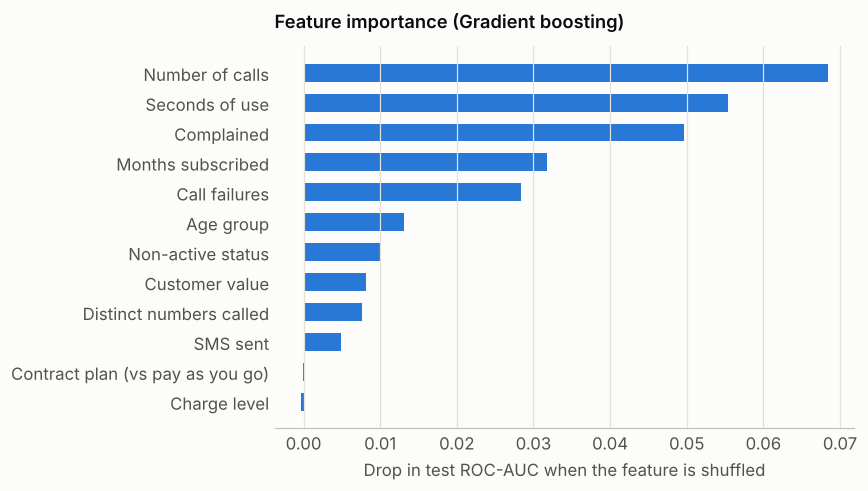

,Permutation importance,Churn rate: low / no,Churn rate: high / yes
Number of calls,0.068,31%,2%
Seconds of use,0.055,35%,0%
Complained,0.050,10%,83%
Months subscribed,0.032,12%,12%
Call failures,0.028,17%,15%
Age group,0.013,15%,16%
Non-active status,0.010,6%,48%
Customer value,0.008,34%,1%
Distinct numbers called,0.008,30%,3%
SMS sent,0.005,21%,1%


Top drivers: **Number of calls**, **Seconds of use**, **Complained**, **Months subscribed**, **Call failures**. Low usage (few calls, few seconds) and a complaint go with much higher churn. Call failures matter in the model even though their simple churn rates look flat, which suggests they matter in combination with other features (for example, failures for customers who use the service little).

In [8]:
imp = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
LABEL = {"complained": "Complained", "seconds_of_use": "Seconds of use", "calls": "Number of calls",
         "sms": "SMS sent", "distinct_numbers_called": "Distinct numbers called", "inactive": "Non-active status",
         "months_subscribed": "Months subscribed", "charge_level": "Charge level", "call_failures": "Call failures",
         "age_group": "Age group", "contract_plan": "Contract plan (vs pay as you go)",
         "customer_value": "Customer value"}
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([LABEL[k] for k in imp.index], imp.values, color=brand.BLUE, height=0.6)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_title(f"Feature importance ({best_name})", fontsize=12)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
fig.tight_layout(); fig.savefig(FIG / "feature_importance.png"); plt.show()
def direction(col: str) -> tuple[float, float]:
    """Churn rate in the lowest vs highest quarter (or 0 vs 1 for yes/no features)."""
    v = df[col]
    if v.nunique() == 2:
        return df.loc[v == v.min(), "churn"].mean(), df.loc[v == v.max(), "churn"].mean()
    lo, hi = v.quantile(0.25), v.quantile(0.75)
    return df.loc[v <= lo, "churn"].mean(), df.loc[v >= hi, "churn"].mean()


dirs = pd.DataFrame([direction(c) for c in imp.index[::-1]], index=imp.index[::-1],
                    columns=["Churn rate: low / no", "Churn rate: high / yes"])
table = pd.concat([imp[::-1].rename("Permutation importance"), dirs], axis=1).rename(index=LABEL)
display(table.style.format({"Permutation importance": "{:.3f}", "Churn rate: low / no": "{:.0%}",
                            "Churn rate: high / yes": "{:.0%}"}))
top = list(imp.index[::-1][:5])
md("Top drivers: " + ", ".join(f"**{LABEL[k]}**" for k in top) + ". Low usage (few calls, few seconds) and a "
   "complaint go with much higher churn. Call failures matter in the model even though their simple churn rates "
   "look flat, which suggests they matter in combination with other features (for example, failures for "
   "customers who use the service little).")

## 8. Recommendations (based on the model, to be tested)

The recommendations are summarised in the one-pager (`output/churn_one_pager.pdf`). They follow from the drivers
above; the model shows associations, so each action should be tested with a control group before rolling it out.

In [9]:
comp_rate = df.groupby("complained")["churn"].mean()
inact_rate = df.groupby("inactive")["churn"].mean()
q = df["seconds_of_use"].quantile(0.25)
low_use_rate = df.loc[df["seconds_of_use"] <= q, "churn"].mean()
plan_rate = df.groupby("contract_plan")["churn"].mean()
results = {
    "n_raw": int(n_before), "n_unique": int(len(df)), "duplicates": int(n_before - len(df)),
    "churn_rate": float(df["churn"].mean()), "n_test": int(len(y_te)), "test_churners": int(y_te.sum()),
    "cv": {k: {m: float(v) for m, v in r.items()} for k, r in cvres.iterrows()},
    "best": best_name, "threshold": threshold, "test_auc": float(auc_te), "test_pr_auc": float(ap_te),
    "test_auc_lr": float(auc_lr), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    "recall": float(tp / (tp + fn)), "precision": float(tp / (tp + fp)),
    "importance": {k: float(v) for k, v in imp[::-1].items()},
    "direction": {k: [float(a), float(b)] for k, (a, b) in dirs.iterrows()},
    "churn_if_complained": float(comp_rate[1]), "churn_if_no_complaint": float(comp_rate[0]),
    "churn_if_inactive": float(inact_rate[1]), "churn_if_active": float(inact_rate[0]),
    "low_use_q25_seconds": float(q), "churn_low_use": float(low_use_rate),
    "churn_contract": float(plan_rate.get(1, np.nan)), "churn_payg": float(plan_rate.get(0, np.nan)),
}
_ = (ROOT / "output" / "results.json").write_text(json.dumps(results, indent=2))
md(f"* Customers who complained churn at **{comp_rate[1]:.0%}** (vs {comp_rate[0]:.0%}).\n"
   f"* Non-active customers churn at **{inact_rate[1]:.0%}** (vs {inact_rate[0]:.0%}).\n"
   f"* The quarter of customers with the lowest usage (≤ {q:,.0f} seconds in 9 months) churn at **{low_use_rate:.0%}**.\n"
   f"* Contract-plan customers churn at {plan_rate.get(1, np.nan):.0%} vs {plan_rate.get(0, np.nan):.0%} on pay as you go.")

* Customers who complained churn at **83%** (vs 10%).
* Non-active customers churn at **48%** (vs 6%).
* The quarter of customers with the lowest usage (≤ 1,459 seconds in 9 months) churn at **35%**.
* Contract-plan customers churn at 3% vs 17% on pay as you go.

## 9. Limitations

* One operator, one period (the data does not say which years); the model must be re-trained and monitored on
  the company's own recent data before use.
* The data has no revenue or cost of retention offers, so the threshold is set by a recall target, not by profit.
* Associations are not causes: a complaint may be a symptom of a problem that also causes churn.
* 3,150 rows (2,850 unique): enough for this comparison, but scores would move by a few points with a different split.

**Source.** Iranian Churn [Dataset] (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5JW3Z
— licence CC BY 4.0.